In [1]:
print("Hello, Spam Detection!")

Hello, Spam Detection!


In [2]:
import pandas as pd

In [3]:
from google.colab import files

uploaded = files.upload()

Saving sms+spam+collection.zip to sms+spam+collection.zip


In [4]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'SMSSpamCollection'

In [5]:
import os

os.listdir()

['.config', 'sms+spam+collection.zip', 'sample_data']

In [6]:
import zipfile

with zipfile.ZipFile("sms+spam+collection.zip", "r") as zip_ref:
    zip_ref.extractall()

print("Dataset extracted!")

Dataset extracted!


In [7]:
import os

os.listdir()

['.config',
 'readme',
 'sms+spam+collection.zip',
 'SMSSpamCollection',
 'sample_data']

In [8]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
df.shape

(5572, 2)

In [10]:
df["label"].value_counts()

,count
label,
ham,4825
spam,747


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [12]:
df.duplicated().sum()

np.int64(403)

In [13]:
df = df.drop_duplicates()

df.shape

(5169, 2)

In [14]:
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


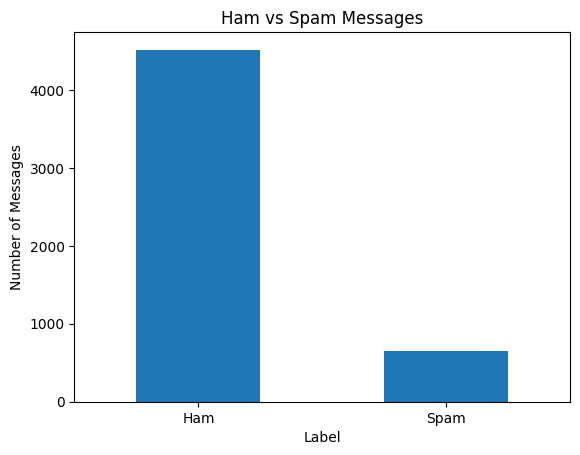

In [17]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("Ham vs Spam Messages")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.xticks([0, 1], ["Ham", "Spam"], rotation=0)
plt.show()

In [18]:
df["message_length"] = df["message"].apply(len)

df[["message", "message_length"]].head()

,message,message_length
0,"Go until jurong point, crazy.. Available only ...",111
1,Ok lar... Joking wif u oni...,29
2,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,U dun say so early hor... U c already then say...,49
4,"Nah I don't think he goes to usf, he lives aro...",61


In [19]:
df.groupby("label")["message_length"].mean()

,message_length
label,
0,70.905890
1,137.704441


In [20]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return text

df["clean_message"] = df["message"].apply(clean_text)

df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df["clean_message"])
y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5169, 8603)
y shape: (5169,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4135, 8603)
Testing data: (1034, 8603)


In [23]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [24]:
y_pred = model.predict(X_test)

print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [25]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9487427466150871


[[903   0]
 [ 53  78]]


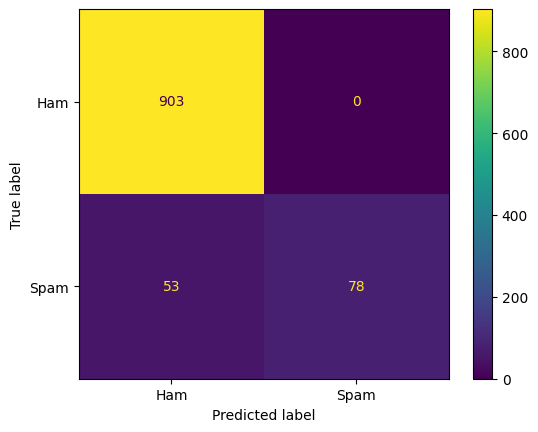

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()
plt.show()

In [27]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.94      1.00      0.97       903
        Spam       1.00      0.60      0.75       131

    accuracy                           0.95      1034
   macro avg       0.97      0.80      0.86      1034
weighted avg       0.95      0.95      0.94      1034



In [28]:
message = ["Congratulations! You have won a free prize. Call now!"]

clean_message = [clean_text(message[0])]

message_vector = vectorizer.transform(clean_message)

prediction = model.predict(message_vector)

if prediction[0] == 1:
    print("Spam 🚨")
else:
    print("Ham ✅")

Spam 🚨


In [29]:
message = ["Hey, are we meeting today at 6 pm?"]

clean_message = [clean_text(message[0])]

message_vector = vectorizer.transform(clean_message)

prediction = model.predict(message_vector)

if prediction[0] == 1:
    print("Spam 🚨")
else:
    print("Ham ✅")

Ham ✅
